# Meridian Capital: Checkpoint 2

We use company valuations and catalysts to add six stocks to our original ETF portfolio. This notebook follows the work from Round 1 performance through stock selection, risk and share quantities.

**Prices:** 6 November 2026 close. **Bloomberg entry:** 7 November. **Risk sample:** 60 monthly USD returns, November 2021–October 2026.

The stock budget is one-third of NAV after losses and distributions. Fees are zero. The final quantities include the extra SPY and Adobe shares bought by the team.

Run the cells in order. The complete repository supplies the inputs in `data/`; saved outputs are included. Packages are listed in `requirements.txt`.

The [companion notebook](valuation_checks.ipynb) develops the cash-flow valuations, implied growth and returns under slower price adjustment. The [team report](submission/AMC2_Report.pdf) brings the analysis together.

## 1. Load the data

The folder search below allows the notebook to run from this directory or the repository root.

In [1]:
from pathlib import Path
from itertools import combinations
from decimal import Decimal, ROUND_FLOOR
import json, math, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from IPython.display import display, Markdown

def find_research_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in [base, base/'research/round-2']:
            if (candidate/'data/policies/implementation_policy.json').is_file() and (candidate/'data/prices').is_dir():
                return candidate.resolve()
    raise FileNotFoundError('Open the notebook with the repository data/ and submission/ folders available.')

ROOT=find_research_root()
RELEASE=ROOT/'submission'
def read_json(relative):return json.loads((ROOT/relative).read_text())
policy=read_json('data/policies/valuation_policy_v4.json')
implementation_policy=read_json('data/policies/implementation_policy.json')
reference=read_json('results/analysis.json')
notes=read_json('data/policies/company_notes.json')
source_register=read_json('data/sources.json')
universe=[r['ticker'] for r in read_json('data/researched_universe.json')]

pd.options.display.max_columns=16
pd.options.display.max_colwidth=100
pd.options.display.float_format=lambda x:f'{x:,.6f}'
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False})
print('Data folder:',ROOT.name)
print('Companies researched:',', '.join(universe))

Data folder: round-2
Companies researched: ADBE, KR, GILD, HRL, BMY, FDS, XOM, HPQ, INTU


## 2. Portfolio requirements

| Item | Our approach |
|---|---|
| Benchmark | Original six-ETF SAA |
| Individual stocks | 3–6 long-only positions |
| Stock proportions | Positive alpha divided by residual variance; negative alpha gives zero weight |
| Tracking error | 2–5% annually, using 60 monthly USD returns |
| Stock allocation | One-third of NAV, following the class instruction |
| Stock universe | US-listed companies |
| Funding | Scale each ETF target to two-thirds of its original weight |
| Additional preferences | Daily TE below 5% and each stock below 8% of NAV |

We compare stock baskets using forecast Information Ratio. The challenge also requires Round 1 Sharpe reporting and the theoretical link between active IR and the SAA's Sharpe ratio.

The controls below can be changed to explore alternative assumptions.

In [2]:
CUTOFF=pd.Timestamp('2026-11-06')
LAST_COMPLETE_MONTH=pd.Timestamp('2026-10-31')
ETFS=['SPY','EEMV','DBC','SCHD','VGSH','STIP']
SAA=pd.Series([.2608,.0966,.2695,.0328,.05,.2903],index=ETFS,name='SAA')
SELECTED=['ADBE','KR','HRL','BMY','XOM','HPQ']
STOCK_FRACTION=1/3
ALPHA_FRACTION=.50  # Allow for uncertainty in valuations and timing.
ERP=.06114
RF_10Y=.0484       # November 5 observation, published November 6.
SAA_EXPECTED_EXCESS=0.0  # SAA excess-return assumption for the IR sensitivity.
FEE_BPS=0
EXTRA_SHARES={'SPY':1,'ADBE':1}  # Extra shares bought after rounding down.

# EPS and multiples are research judgements. Edit here to explore sensitivity.
VALUATION_INPUTS={
    'ADBE':{'eps':18.145,'pe':16.0},
    'KR':{'eps':5.2,'pe':15.0},
    'GILD':{'eps':8.855,'pe':20.0},
    'HRL':{'eps':1.48,'pe':17.0},
    'BMY':{'eps':6.45,'pe':11.0},
    'FDS':{'eps':17.25,'pe':21.5},
    'XOM':{'eps':10.0,'pe':18.0},
    'HPQ':{'eps':2.38,'pe':13.5},
    'INTU':{'eps':20.24,'pe':20.0},
}
FINAL_CASE=(SELECTED==reference['stocks'] and np.isclose(STOCK_FRACTION,1/3)
            and ALPHA_FRACTION==policy['alpha_fraction'] and ERP==policy['erp'] and RF_10Y==policy['rf10y']
            and FEE_BPS==0 and EXTRA_SHARES==implementation_policy['extra_shares']
            and SAA_EXPECTED_EXCESS==0 and np.allclose(SAA.to_numpy(),reference['benchmark'][:6])
            and CUTOFF==pd.Timestamp('2026-11-06') and LAST_COMPLETE_MONTH==pd.Timestamp('2026-10-31')
            and all(VALUATION_INPUTS[t]['eps']==policy['valuation'][t]['eps']
                    and VALUATION_INPUTS[t]['pe']==policy['valuation'][t]['pe'] for t in universe))
print('Case:', '6 November portfolio' if FINAL_CASE else 'Alternative assumptions')

Case: 6 November portfolio


### Price and return series

Adjusted prices supply total returns for risk estimates and historical tests. Share quantities use raw USD closes rounded to cents. Dividend corrections and the saved Treasury-rate series are included with the source data.

In [3]:
dividend_overrides=read_json('data/dividend_overrides.json')

def read_prices(ticker):
    raw=read_json(f'data/prices/{ticker}.json')['chart']['result'][0]
    index=pd.to_datetime(raw['timestamp'],unit='s',utc=True).tz_convert('America/New_York').tz_localize(None).normalize()
    frame=pd.DataFrame({'close':raw['indicators']['quote'][0]['close'],
                        'adjusted':raw['indicators']['adjclose'][0]['adjclose']},index=index)
    fallback=ROOT/f'data/price_fallback/{ticker}.json'
    if fallback.exists():
        extra=json.loads(fallback.read_text())['chart']['result'][0]
        ii=pd.to_datetime(extra['timestamp'],unit='s',utc=True).tz_convert('America/New_York').tz_localize(None).normalize()
        frame=frame.combine_first(pd.DataFrame({'close':extra['indicators']['quote'][0]['close'],
                 'adjusted':extra['indicators']['adjclose'][0]['adjclose']},index=ii))
    frame=frame.loc[:CUTOFF].dropna()
    events={str(pd.Timestamp(v['date'],unit='s',tz='UTC').tz_convert('America/New_York').date()):v['amount']
            for v in raw.get('events',{}).get('dividends',{}).values()}
    for event in dividend_overrides:
        if event['ticker']!=ticker:continue
        date=pd.Timestamp(event['ex_date'])
        if event['ex_date'] not in events:
            frame.loc[frame.index<date,'adjusted']*=1-event['amount']/frame.loc[frame.index<date,'close'].iloc[-1]
            events[event['ex_date']]=event['amount']
    assert frame.index[-1]==CUTOFF,(ticker,'Missing required close')
    return frame,events

TICKERS=ETFS+universe
price_frames={};dividends={}
for ticker in TICKERS:price_frames[ticker],dividends[ticker]=read_prices(ticker)
adjusted=pd.concat({t:price_frames[t].adjusted for t in TICKERS},axis=1).dropna()
assert all(price_frames[t].adjusted.reindex(adjusted.index).notna().all() for t in TICKERS)
daily=adjusted.pct_change(fill_method=None).iloc[1:]
monthly=adjusted.resample('ME').last().loc[:LAST_COMPLETE_MONTH].pct_change(fill_method=None).dropna()
rates=pd.read_csv(ROOT/'data/fred_history.csv',index_col=0,parse_dates=True).DGS1MO
rf_monthly=rates.resample('ME').mean().reindex(monthly.index)/1200
excess=monthly.sub(rf_monthly,axis=0)
calibration=monthly.tail(60);calibration_excess=excess.tail(60)
assert len(calibration)==60 and calibration.index[0]==pd.Timestamp('2021-11-30')
assert calibration.index[-1]==LAST_COMPLETE_MONTH and calibration_excess.notna().all().all()
display(pd.DataFrame({'First calibration month':[calibration.index[0].date()],
                      'Last calibration month':[calibration.index[-1].date()],
                      'Monthly observations':[len(calibration)],'Last price':[adjusted.index[-1].date()]}))

,First calibration month,Last calibration month,Monthly observations,Last price
0,2021-11-30,2026-10-31,60,2026-11-06


## 3. Round 1 performance and the rebalance budget

Our original portfolio combines US and emerging-market equities, commodities and short-term bonds. Its target annual volatility was 8%.

We calculate daily NAV from the original shares, closing prices and dividend entitlements. Distributions enter NAV on the ex-date; payment then moves the receivable into cash. The historical tests later in the notebook use adjusted prices, which assume reinvestment.

,SAA weight,Opening USD,Ending USD incl. distributions,P&L USD,Contribution to initial NAV
SPY,26.08%,"26,079,489.25","25,124,124.01","-955,365.24",-0.955%
EEMV,9.66%,"9,660,003.00","9,313,953.10","-346,049.90",-0.346%
DBC,26.95%,"26,950,027.44","25,192,764.24","-1,757,263.20",-1.757%
SCHD,3.28%,"3,280,012.80","3,358,312.96","78,300.16",0.078%
VGSH,5.00%,"5,000,049.99","5,031,156.21","31,106.22",0.031%
STIP,29.03%,"29,030,405.40","29,094,745.93","64,340.53",0.064%


,Round 1
Ending NAV USD,"97,115,068.575610"
Total return,-0.028849
Annualised daily volatility,0.081413
Annualised daily Sharpe,-6.496739
Daily observations,15.000000


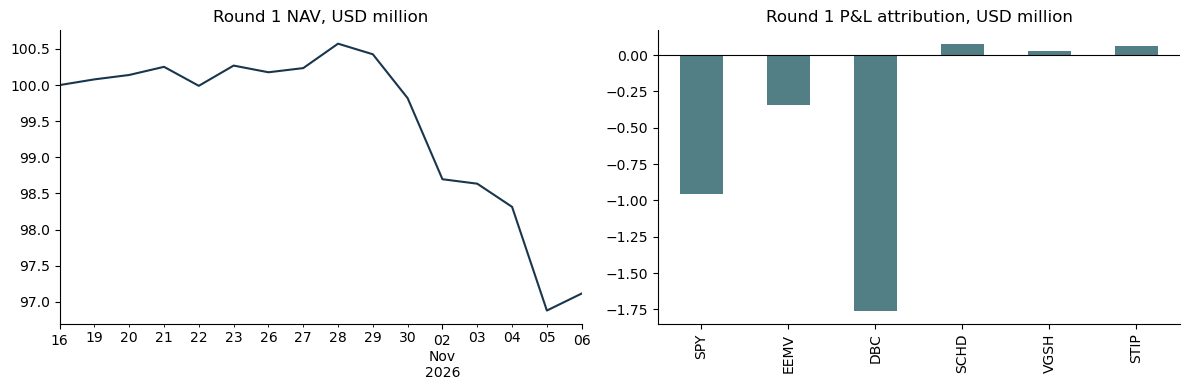

In [4]:
opening_shares=pd.Series([34169,133610,798756,95488,86671,288630],index=ETFS)
opening_cash=12.12
round1_components={}
for ticker in ETFS:
    closes=price_frames[ticker].close.loc['2026-10-16':CUTOFF].round(2)
    credits=np.array([sum(amount for date,amount in dividends[ticker].items()
                         if closes.index[0]<pd.Timestamp(date)<=day) for day in closes.index])
    round1_components[ticker]=opening_shares[ticker]*(closes+credits)
round1_components=pd.DataFrame(round1_components)
round1_nav=round1_components.sum(axis=1)+opening_cash
round1_returns=round1_nav.pct_change().dropna()
NAV=float(round1_nav.iloc[-1])
round1_rf=rates.reindex(round1_nav.index).ffill()/100/252
round1_vol=round1_returns.std(ddof=1)*np.sqrt(252)
round1_sharpe=(round1_returns-round1_rf.reindex(round1_returns.index)).mean()/round1_returns.std(ddof=1)*np.sqrt(252)
attribution=pd.DataFrame({'SAA weight':SAA,'Opening USD':round1_components.iloc[0],
                          'Ending USD incl. distributions':round1_components.iloc[-1]})
attribution['P&L USD']=attribution.iloc[:,2]-attribution.iloc[:,1]
attribution['Contribution to initial NAV']=attribution['P&L USD']/round1_nav.iloc[0]
assert np.isclose(round1_nav.iloc[0],100_000_000)
assert np.isclose(attribution['P&L USD'].sum(),NAV-round1_nav.iloc[0])
display(attribution.style.format({'SAA weight':'{:.2%}','Opening USD':'{:,.2f}',
 'Ending USD incl. distributions':'{:,.2f}','P&L USD':'{:,.2f}','Contribution to initial NAV':'{:.3%}'}))
display(pd.Series({'Ending NAV USD':NAV,'Total return':NAV/round1_nav.iloc[0]-1,
                   'Annualised daily volatility':round1_vol,'Annualised daily Sharpe':round1_sharpe,
                   'Daily observations':len(round1_returns)}).to_frame('Round 1'))
fig,axes=plt.subplots(1,2,figsize=(12,4))
(round1_nav/1e6).plot(ax=axes[0],title='Round 1 NAV, USD million',color='#18364D')
(attribution['P&L USD']/1e6).plot.bar(ax=axes[1],title='Round 1 P&L attribution, USD million',color='#527F86')
axes[1].axhline(0,color='black',lw=.8);plt.tight_layout();plt.show()

DBC was the largest contributor to the loss. Realized annual volatility remained within the original 7–9% band. With only 15 daily returns, the annualized Sharpe ratio is particularly sensitive to individual losses.

In [5]:
stock_budget=NAV*STOCK_FRACTION
display(pd.Series({'Post-loss NAV USD':NAV,'Individual-stock target USD':stock_budget,
                   'Retained ETF target USD':NAV-stock_budget,'Trading fee bps':FEE_BPS}).to_frame('Checkpoint 2 budget'))
print(f'One-third of post-loss NAV: ${stock_budget:,.2f}.')

,Checkpoint 2 budget
Post-loss NAV USD,"97,115,068.575610"
Individual-stock target USD,"32,371,689.525203"
Retained ETF target USD,"64,743,379.050407"
Trading fee bps,0.000000


One-third of post-loss NAV: $32,371,689.53.


### Distributions included in NAV

The issuer histories checked on 8 November show:

- [VGSH](https://www.vanguardsouthamerica.com/en/product/etf/fixed-income/3142/vanguard-short-term-treasury-etf): $0.1889 per share, ex 2 November, paid 4 November.
- [STIP](https://www.ishares.com/us/products/239450/ishares-05-year-tips-bond-etf): $0.292917 per share, ex 2 November, paid 5 November.

Our opening holdings were entitled to both payments. Each distribution is counted once. The October VGSH distribution falls before the opening portfolio date.

In [6]:
distribution_rows=[]
for event in dividend_overrides:
    if event['ticker'] in ETFS and round1_nav.index[0] < pd.Timestamp(event['ex_date']) <= CUTOFF:
        shares=int(opening_shares[event['ticker']])
        distribution_rows.append({'Ticker':event['ticker'],'Ex-date':event['ex_date'],
                                  'Payment date':event['pay_date'],'USD per share':event['amount'],
                                  'Entitled shares':shares,'Income USD':shares*event['amount']})
nav_dividends=pd.DataFrame(distribution_rows)
security_value=sum(int(opening_shares[t])*round(float(price_frames[t].close.loc[CUTOFF]),2) for t in ETFS)
nav_breakdown=pd.Series({'Closing securities USD':security_value,'Opening cash USD':opening_cash,
                        'Entitled distributions USD':nav_dividends['Income USD'].sum(),
                        'Total NAV USD':NAV,'One-third stock target USD':NAV*STOCK_FRACTION})
np.testing.assert_allclose(security_value+opening_cash+nav_dividends['Income USD'].sum(),NAV,atol=.000001,rtol=0)
display(nav_dividends)
display(nav_breakdown.to_frame('Amount').style.format('{:,.6f}'))
print(f'Verified closing-price NAV: ${NAV:,.2f}; dividends are counted once.')

,Ticker,Ex-date,Payment date,USD per share,Entitled shares,Income USD
0,VGSH,2026-11-02,2026-11-04,0.188900,86671,"16,372.151900"
1,STIP,2026-11-02,2026-11-05,0.292917,288630,"84,544.633710"


,Amount
Closing securities USD,"97,014,139.670000"
Opening cash USD,12.120000
Entitled distributions USD,"100,916.785610"
Total NAV USD,"97,115,068.575610"
One-third stock target USD,"32,371,689.525203"


Verified closing-price NAV: $97,115,068.58; dividends are counted once.


## 4. Earnings valuations

We estimate value as **normalized EPS × chosen P/E**. The multiple reflects the company's business, peers, cash generation and risks.

- Adobe uses GAAP EPS guidance, including stock compensation.
- HP's normalized EPS excludes the $0.19 tariff-refund benefit.
- BMY's EPS includes the disclosed licensing/IPRD cost.
- Kroger uses adjusted guidance; the unquantified refund benefit creates uncertainty around recurring earnings.
- Hormel's multiple assumes a recovery in margins.
- Exxon's $10 EPS is our assumption for earnings across the commodity cycle.

The comparison covers the nine companies we researched.

In [7]:
entry_prices=pd.Series({t:round(float(price_frames[t].close.iloc[-1]),2) for t in TICKERS})
values=pd.DataFrame.from_dict(VALUATION_INPUTS,orient='index').loc[universe]
values['Price USD']=entry_prices.reindex(universe)
values['Value USD']=values.eps*values.pe
values['Upside V/P-1']=values['Value USD']/values['Price USD']-1
values['Discount 1-P/V']=1-values['Price USD']/values['Value USD']
values['Break-even P/E']=values['Price USD']/values.eps
display(values.style.format({'eps':'{:.3f}','pe':'{:.1f}','Price USD':'${:.2f}',
 'Value USD':'${:.2f}','Upside V/P-1':'{:.2%}','Discount 1-P/V':'{:.2%}','Break-even P/E':'{:.2f}'}))
display(pd.DataFrame({'Earnings basis':[policy['valuation'][t]['basis'] for t in universe],
                      'Catalyst assumption':[policy['valuation'][t]['catalyst'] for t in universe]},index=universe))

,eps,pe,Price USD,Value USD,Upside V/P-1,Discount 1-P/V,Break-even P/E
ADBE,18.145,16.0,$239.30,$290.32,21.32%,17.57%,13.19
KR,5.200,15.0,$67.70,$78.00,15.21%,13.21%,13.02
GILD,8.855,20.0,$166.89,$177.10,6.12%,5.77%,18.85
HRL,1.480,17.0,$21.95,$25.16,14.62%,12.76%,14.83
BMY,6.450,11.0,$62.14,$70.95,14.18%,12.42%,9.63
FDS,17.250,21.5,$327.89,$370.88,13.11%,11.59%,19.01
XOM,10.000,18.0,$165.87,$180.00,8.52%,7.85%,16.59
HPQ,2.380,13.5,$28.46,$32.13,12.90%,11.42%,11.96
INTU,20.240,20.0,$341.50,$404.80,18.54%,15.64%,16.87


,Earnings basis,Catalyst assumption
ADBE,FY26 company GAAP EPS midpoint18.12-18.17; SBC included.,"December9 results, confirmed issuer calendar."
KR,"FY26 company adjusted EPS midpoint5.10-5.30, reaffirmed October20; past fulfilment impairment ex...","December3 results, confirmed issuer announcement."
GILD,FY26 nonGAAP midpoint-1.025 plus issuer-quantified9.88 IPRD impact; acquisition cash remains a r...,ASH December12-15 and FDA target December23; decision not guaranteed.
HRL,FY26 adjusted guidance1.45-1.51 midpoint; GAAP1.06-1.12 affected by divestiture/impairment/legal...,"December3 FY26 results and first FY27 outlook, confirmed issuer calendar; Brakebush integration/..."
BMY,FY26 company nonGAAP6.35-6.55 midpoint; retains0.60 acquired-IPRD/licensing impact rather than a...,Issuer October29 presentation expects remaining2026 Sotyktu SLE and other clinical readouts; con...
FDS,FY27 company GAAP EPS17.00-17.50 midpoint; excludes neither SBC nor intangible amortization. Sep...,"November10 Investor Day, confirmed primary announcement; expected December FY27Q1 results date n..."
XOM,"Judgemental normalized EPS of USD 10.00, below Yahoo FY2027 consensus USD 12.01328 and close to ...",Management expects Uaru startup in Q4 and a press release with 2027 planning metrics later in Q4...
HPQ,FY2026 company GAAP EPS midpoint 2.57 less 0.19 of tariff refunds = 2.38. Do not capitalize the ...,"FY2026 results and FY2027 guidance; PC pricing/memory costs, print supplies and cash generation."
INTU,FY2027 GAAP EPS guidance midpoint (20.12 to 20.36),November 19 Q1 FY2027 results; test delivery against company guidance and the first quarter unde...


### Adobe example

The calculation below shows its earnings value, upside from entry and margin of safety. Whether the discount closes during the challenge depends on the December outlook and the market's response.

In [8]:
adobe=values.loc['ADBE']
print(f"EPS ${adobe.eps:.3f} × {adobe.pe:.1f} = estimated value ${adobe['Value USD']:.2f}")
print(f"Entry ${adobe['Price USD']:.2f}; upside {adobe['Upside V/P-1']:.2%}; discount to value {adobe['Discount 1-P/V']:.2%}")

EPS $18.145 × 16.0 = estimated value $290.32
Entry $239.30; upside 21.32%; discount to value 17.57%


## 5. Financial quality, cash flow and catalysts

We compare profitability, cash generation, leverage and shareholder payouts with each company's history and peers. The six ratios are calculated from the saved annual statements. Negative book equity makes ROE and debt/equity unavailable for HP.

Catalysts give us dates to watch. The news itself can be positive or negative.

In [9]:
annual=pd.read_csv(ROOT/'data/annual_statements.csv').sort_values(['ticker','fiscal_end'])
annual['FCF']=annual.OperatingCashFlow-annual.CapitalExpenditure.abs()
annual['ROE']=annual.NetIncome/annual.StockholdersEquity.where(annual.StockholdersEquity>0)
annual['FCF_margin']=annual.FCF/annual.TotalRevenue
annual['Revenue_growth']=annual.groupby('ticker').TotalRevenue.pct_change(fill_method=None)
annual['Gross_margin']=annual.GrossProfit/annual.TotalRevenue
annual['Debt_equity']=annual.TotalDebt/annual.StockholdersEquity.where(annual.StockholdersEquity>0)
annual['Payout_FCF']=(annual.CashDividendsPaid.abs()+annual.RepurchaseOfCapitalStock.abs())/annual.FCF.where(annual.FCF>0)
peer_sets=read_json('data/peer_sets.json')
metrics=['ROE','FCF_margin','Revenue_growth','Gross_margin','Debt_equity','Payout_FCF']
quality_rows=[]
for ticker in SELECTED:
    history=annual[annual.ticker==ticker]
    peers=annual[annual.ticker.isin(peer_sets.get(ticker,[]))].groupby('ticker').tail(1)
    for metric in metrics:
        latest=history.iloc[-1][metric];prior=history.iloc[:-1][metric].mean();peer=peers[metric].median()
        lower=metric in ['Debt_equity','Payout_FCF']
        flag=None if not all(pd.notna(z) for z in [latest,prior,peer]) else bool(latest>max(prior,peer) if lower else latest<min(prior,peer))
        quality_rows.append({'Stock':ticker,'Metric':metric,'Latest':latest,'Prior mean':prior,
                             'Peer median':peer,'Warning':flag})
quality=pd.DataFrame(quality_rows)
display(quality)
print('Warning: weaker than both history and peers. Fiscal year-ends differ across companies.')

,Stock,Metric,Latest,Prior mean,Peer median,Warning
0,ADBE,ROE,0.613439,0.353760,0.240417,False
1,ADBE,FCF_margin,0.414489,0.381285,0.346827,False
2,ADBE,Revenue_growth,0.105278,0.105200,0.138973,False
3,ADBE,Gross_margin,0.892675,0.882033,0.776761,False
4,ADBE,Debt_equity,0.571969,0.335361,0.443397,True
5,ADBE,Payout_FCF,1.145047,0.908698,0.884587,True
6,KR,ROE,0.171419,0.243813,0.219772,True
7,KR,FCF_margin,0.023408,0.013626,0.020925,False
8,KR,Revenue_growth,0.003528,-0.003711,0.034601,False
9,KR,Gross_margin,0.233010,0.221251,0.271805,False


In [10]:
def statement_frame(ticker,frequency='quarterly'):
    raw=read_json(f'data/statements/{ticker}.json')['timeseries']['result'];columns={}
    for item in raw:
        kind=item['meta']['type'][0]
        if kind.startswith(frequency):
            columns[kind[len(frequency):]]={v['asOfDate']:v['reportedValue']['raw'] for v in item.get(kind,[])}
    frame=pd.DataFrame(columns).sort_index()
    frame=frame[frame.TotalRevenue.notna()].copy()
    for event in read_json('data/issuer_overrides.json'):
        if event['ticker']==ticker and event['frequency']==frequency and event['period'] in frame.index:
            frame.loc[event['period'],event['field']]=event['value']
    return frame

quotes={}
for file in ['quotes_prior.json','quotes_energy.json','quotes.json','quotes_extension.json']:
    for item in read_json('data/'+file)['quoteResponse']['result']:quotes[item['symbol']]=item

def cash_value(cash_per_share,k,growth,terminal_growth):
    if cash_per_share is None or k<=terminal_growth:return np.nan
    interim=sum(cash_per_share*(1+growth)**year/(1+k)**year for year in range(1,6))
    terminal=cash_per_share*(1+growth)**5*(1+terminal_growth)/(k-terminal_growth)/(1+k)**5
    return interim+terminal

cash_per_share={}
for ticker in SELECTED:
    quarters=statement_frame(ticker).tail(4)
    assert len(quarters)==4
    fields=['OperatingCashFlow','CapitalExpenditure','StockBasedCompensation']
    complete=all(c in quarters and quarters[c].notna().all() for c in fields)
    owner_cash=(quarters.OperatingCashFlow.sum()-quarters.CapitalExpenditure.abs().sum()-quarters.StockBasedCompensation.sum()) if complete else None
    owner_cash=policy['valuation'][ticker].get('cash_base_override',owner_cash)
    cash_per_share[ticker]=owner_cash/quotes[ticker]['sharesOutstanding'] if owner_cash is not None else None

for ticker in SELECTED:
    note=notes[ticker]
    display(Markdown(f"**{ticker}: {note['name']}**\n\n{note['trap']}\n\n**New information expected:** {note['event']}\n\n**What would undermine it:** {note['fail']}"))

**ADBE: Adobe**

Qualified value case: cash supports a value above price, but the lower cash cross-check narrows the apparent earnings-based cushion. A software rerating is not assured.

**New information expected:** Issuer calendar: December9 FY26 results. The useful new information is recurring-revenue growth, paid AI monetisation, margins and the FY27 outlook. We need better evidence of earnings sustainability, not merely a known reporting date.

**What would undermine it:** AI competition weakens renewals or pricing; cash generation deteriorates; FY27 guidance fails to support normalized earnings.

**KR: Kroger**

Qualified positive: cash value is close to earnings value, but the largest alpha/residual score creates the largest position. Its resulting weight slightly exceeds the8% research preference. No discretionary increase is justified.

**New information expected:** Issuer-announced December3 Q3 results. Watch same-store demand, margin, free cash and execution of the October strategy update. The October20 update was already public before entry and is not a new future event.

**What would undermine it:** Sales or margins weaken, cash conversion disappoints, or buybacks rely on rising borrowing instead of sustainable cash.

**HRL: Hormel Foods**

Moderate-conviction recovery case. The cash proxy supports value, but dividend coverage is only modest and the prior annual payout ratio is a warning. A dividend cut or acquisition-funded cash shortfall would undermine the thesis.

**New information expected:** Confirmed December3 FY26 results and FY27 outlook, including the new CEO's execution priorities. The useful catalyst is evidence of cash recovery and a credible outlook. Acquisition completion itself may occur after the challenge cutoff.

**What would undermine it:** Weak FY27 guidance, further retail-volume losses, poor cash conversion, a dividend funding problem, or unexpectedly expensive acquisition financing.

**BMY: Bristol Myers Squibb**

Qualified value case, with three annual quality warnings. No-growth cash support is useful, but it is not protection against a patent-driven decline. A constant-growth DDM would underrepresent that discontinuity.

**New information expected:** The October29 issuer presentation expects remaining2026 SotyktuSLE and milvexian secondary-stroke readouts. Exact days are unconfirmed and could slip beyond December27. Already-reported trials are not counted again. These are clinical results, not assumed regulatory approvals. Milvexian already failed in the separate ACS indication; a positive stroke result must not be presumed from its mechanism.

**What would undermine it:** Disappointing clinical data, greater patent erosion, declining cash, or acquisition/debt demands that undermine shareholder distributions.

**XOM: ExxonMobil**

Moderate-low conviction. The valuation cushion is thin for a cyclical producer and the event timing is uncertain. Raw FCF is useful evidence, but Yahoo supplies no SBC series, so no after-SBC cash value is fabricated.

**New information expected:** The issuer's Q3 call expects Uaru startup and a release of2027planning metrics duringQ4. There is no formal December investor-day event. Timing is unconfirmed and may fall after December27; project execution and planning detail must provide new information.

**What would undermine it:** Lower oil/refining margins, project delays, capital spending overruns, or payouts that depend on extrapolating peak-cycle cash.

**HPQ: HP Inc.**

Qualified, modest-size cash case. Printing decline and weak unit volumes can erode profits. Normalized cash value supports the earnings value, but the cushion is not large. The modest position improves expected basketIR without making the portfolio depend heavily on the PC cycle.

**New information expected:** Confirmed November24FY26results and FY27outlook. The key new information is normalized cash, printing trends, pricing/memory costs and the outlook after the tariff-refund benefit expires. Later investor conferences are supplementary rather than the main catalyst.

**What would undermine it:** FY27guidance or normalized cash weakens, printing decline accelerates, or shareholder distributions rely on borrowing.

This first cash screen uses a simple cash proxy. The companion notebook provides the detailed FCFF and FCFE calculations, including issuer-corrected debt, cash and stock compensation.

BMY and Exxon's undated events could fall after the challenge cutoff. Kroger and Hormel both report on 3 December.

## 6. Beta and residual risk

We regress monthly excess stock returns on SAA excess returns over the same 60-month sample:

\[
r_i-r_f=a_i+\beta_{i,SAA}(r_{SAA}-r_f)+\epsilon_i.
\]

Residual variance is annualized by multiplying by 12. A separate regression on SPY provides the market beta used in the discount rate. Our forecast alphas come from the valuations in the next section.

,Beta SAA,Beta SPY,Annual residual variance
Stock,,,
ADBE,2.086415,1.365264,0.121203
KR,1.255040,0.361005,0.046933
GILD,0.858235,0.345541,0.054441
HRL,0.520915,0.274479,0.052727
BMY,0.988856,0.211909,0.055456
FDS,1.205613,0.691301,0.070778
XOM,1.680569,0.171638,0.058157
HPQ,2.121552,1.181196,0.090452
INTU,1.448441,0.903838,0.122336


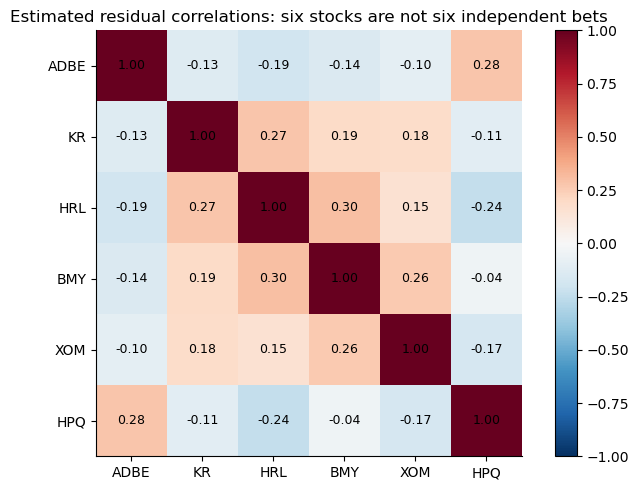

In [11]:
saa_excess=calibration_excess[ETFS].dot(SAA)
market_excess=calibration_excess.SPY
design=np.column_stack([np.ones(60),saa_excess])
market_design=np.column_stack([np.ones(60),market_excess])
residuals=pd.DataFrame(index=calibration.index)
risk_rows=[]
for ticker in universe:
    y=calibration_excess[ticker].to_numpy()
    coefficients=np.linalg.lstsq(design,y,rcond=None)[0]
    market_beta=np.linalg.lstsq(market_design,y,rcond=None)[0][1]
    residuals[ticker]=y-design@coefficients
    risk_rows.append({'Stock':ticker,'Beta SAA':coefficients[1],'Beta SPY':market_beta,
                      'Annual residual variance':residuals[ticker].var(ddof=1)*12})
risk_inputs=pd.DataFrame(risk_rows).set_index('Stock')
residual_cov=residuals.cov()*12
display(risk_inputs)
fig,ax=plt.subplots(figsize=(7,5))
corr=residuals[SELECTED].corr()
img=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(SELECTED)),SELECTED);ax.set_yticks(range(len(SELECTED)),SELECTED)
for i in range(len(SELECTED)):
    for j in range(len(SELECTED)):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=9)
ax.set_title('Estimated residual correlations: six stocks are not six independent bets')
fig.colorbar(img,ax=ax);plt.tight_layout();plt.show()

## 7. Alpha assumptions and stock proportions

We use the class valuation-to-alpha calculation and apply a common 50% haircut:

\[
k_i=r_{10y}+\beta_{i,SPY}\,ERP,\qquad
\alpha_i^{full}=(1+k_i)(V_i/P_i-1),\qquad
\alpha_i^{base}=0.5\alpha_i^{full}.
\]

We chose the haircut to allow for uncertainty over valuation and timing. The estimates are annual, while the next rebalance is in November.

In [12]:
forecast=values.join(risk_inputs)
forecast['k']=RF_10Y+forecast['Beta SPY']*ERP
forecast['Full annual alpha']=(1+forecast.k)*forecast['Upside V/P-1']
forecast['Base annual alpha']=ALPHA_FRACTION*forecast['Full annual alpha']
forecast['TB score']=forecast['Base annual alpha'].clip(lower=0)/forecast['Annual residual variance']
display(forecast[['Value USD','Price USD','k','Full annual alpha','Base annual alpha','Annual residual variance','TB score']])

def basket_weights(names,alphas=None):
    aa=forecast.loc[names,'Base annual alpha'] if alphas is None else pd.Series(alphas,index=names)
    scores=aa.clip(lower=0)/forecast.loc[names,'Annual residual variance']
    if scores.sum()<=0:raise ValueError('At least one positive alpha is needed to form the stock basket.')
    return scores/scores.sum()

q=basket_weights(SELECTED)
half_q=basket_weights(SELECTED,forecast.loc[SELECTED,'Base annual alpha']*.5)
np.testing.assert_allclose(q,half_q,atol=1e-12)
display(pd.DataFrame({'Base alpha':forecast.loc[SELECTED,'Base annual alpha'],
                      'Residual variance':forecast.loc[SELECTED,'Annual residual variance'],
                      'TB score':forecast.loc[SELECTED,'TB score'],'Weight within stocks':q,
                      'Weight in total NAV':q*STOCK_FRACTION}))
print('A common alpha scaling changes IR but cancels out of normalised proportions.')

,Value USD,Price USD,k,Full annual alpha,Base annual alpha,Annual residual variance,TB score
ADBE,290.320000,239.300000,0.131872,0.241321,0.120661,0.121203,0.995525
KR,78.000000,67.700000,0.070472,0.162864,0.081432,0.046933,1.735048
GILD,177.100000,166.890000,0.069526,0.065432,0.032716,0.054441,0.600939
HRL,25.160000,21.950000,0.065182,0.155774,0.077887,0.052727,1.477174
BMY,70.950000,62.140000,0.061356,0.150475,0.075238,0.055456,1.356704
FDS,370.875000,327.890000,0.090666,0.142982,0.071491,0.070778,1.010067
XOM,180.000000,165.870000,0.058894,0.090204,0.045102,0.058157,0.775519
HPQ,32.130000,28.460000,0.120618,0.144507,0.072254,0.090452,0.798804
INTU,404.800000,341.500000,0.103661,0.204573,0.102287,0.122336,0.836111


,Base alpha,Residual variance,TB score,Weight within stocks,Weight in total NAV
ADBE,0.120661,0.121203,0.995525,0.139453,0.046484
KR,0.081432,0.046933,1.735048,0.243046,0.081015
HRL,0.077887,0.052727,1.477174,0.206923,0.068974
BMY,0.075238,0.055456,1.356704,0.190047,0.063349
XOM,0.045102,0.058157,0.775519,0.108635,0.036212
HPQ,0.072254,0.090452,0.798804,0.111896,0.037299


A common alpha scaling changes IR but cancels out of normalised proportions.


Kroger receives a larger weight than Adobe because its alpha-to-residual-variance score is higher. A common reduction in all alphas lowers forecast IR and leaves the normalized stock proportions unchanged.

## 8. Comparing stock baskets

We apply the same stock-proportion and ETF-funding rules to each 3–6-stock combination. The monthly TE band determines eligibility.

- **Course IR:** \(\sqrt{\sum_i \alpha_i^2/\sigma_i^2(\epsilon_i)}\), assuming independent residuals.
- **Full-residual IR:** basket alpha divided by residual volatility, including measured correlations.
- **Portfolio active IR:** expected portfolio-minus-SAA return divided by tracking error.

Realized historical IR is calculated later.

In [13]:
benchmark=SAA.reindex(TICKERS,fill_value=0)
def covariance_models(train_monthly,train_daily):
    a=train_daily.tail(252).to_numpy();weights=2**(-np.arange(len(a))[::-1]/63);weights/=weights.sum()
    centered=a-(a*weights[:,None]).sum(axis=0)
    return {'Monthly60':train_monthly.tail(60).cov()*12,
            'Daily252':train_daily.tail(252).cov()*252,
            'Daily63':train_daily.tail(63).cov()*252,
            'EWMA252':pd.DataFrame(centered.T@(centered*weights[:,None])/(1-(weights*weights).sum())*252,index=TICKERS,columns=TICKERS)}
covariances=covariance_models(monthly,daily)

def portfolio_weights(names,stock_q=None,etf_weights=None):
    stock_q=basket_weights(names) if stock_q is None else stock_q
    w=pd.Series(0.,index=TICKERS)
    w.loc[ETFS]=SAA*(1-STOCK_FRACTION) if etf_weights is None else pd.Series(etf_weights).reindex(ETFS)
    w.loc[names]=stock_q*STOCK_FRACTION
    return w

def portfolio_metrics(names,stock_q=None,alphas=None,etf_weights=None):
    stock_q=basket_weights(names,alphas) if stock_q is None else stock_q
    aa=forecast.loc[names,'Base annual alpha'] if alphas is None else pd.Series(alphas,index=names)
    w=portfolio_weights(names,stock_q,etf_weights);delta=w-benchmark
    covariance=residual_cov.loc[names,names].to_numpy()
    alpha=float(stock_q@aa);res_vol=float(np.sqrt(stock_q.to_numpy()@covariance@stock_q.to_numpy()))
    te={name:float(np.sqrt(max(delta.to_numpy()@matrix.to_numpy()@delta.to_numpy(),0)))for name,matrix in covariances.items()}
    beta=float((w.loc[ETFS].sum())+STOCK_FRACTION*(stock_q@forecast.loc[names,'Beta SAA'])) if etf_weights is None else float(calibration_excess.dot(w).cov(saa_excess)/saa_excess.var())
    active_alpha=float(w.loc[names]@aa)
    return {'stocks':tuple(names),'Course IR':float(np.sqrt(np.sum(aa.clip(lower=0)**2/forecast.loc[names,'Annual residual variance']))),
            'Full residual IR':alpha/res_vol,'Monthly TE':te['Monthly60'],'Daily63 TE':te['Daily63'],
            'Max stock':float((stock_q*STOCK_FRACTION).max()),'Eligible':.02<=te['Monthly60']<=.05,
            'Portfolio beta SAA':beta,'Annual alpha/NAV':active_alpha,
            'Expected active IR':(active_alpha+(beta-1)*SAA_EXPECTED_EXCESS)/te['Monthly60']}

positive=forecast.index[forecast['Base annual alpha']>0].tolist()
candidate_records=[portfolio_metrics(list(names)) for count in range(3,7) for names in combinations(positive,count)]
candidates=pd.DataFrame(candidate_records)
eligible=candidates[candidates.Eligible]
if eligible.empty:raise ValueError('No basket satisfies the monthly TE range under these assumptions.')
pure_max=eligible.loc[eligible['Full residual IR'].idxmax()]
headline_max=eligible.loc[eligible['Course IR'].idxmax()]
selected_metrics=portfolio_metrics(SELECTED)
comparison=pd.DataFrame([selected_metrics,pure_max.to_dict(),headline_max.to_dict()],index=['Selected six','Pure full-residual maximum','Highest course-formula IR'])
display(comparison.drop(columns='Eligible'))
print(f'Enumerated {len(candidates)} subsets; {len(eligible)} satisfy official monthly TE.')

,stocks,Course IR,Full residual IR,Monthly TE,Daily63 TE,Max stock,Portfolio beta SAA,Annual alpha/NAV,Expected active IR
Selected six,"(ADBE, KR, HRL, BMY, XOM, HPQ)",0.755798,0.695860,0.039190,0.077403,0.081015,1.103890,0.026673,0.680603
Pure full-residual maximum,"(ADBE, KR, HRL, BMY, HPQ)",0.732293,0.697576,0.040871,0.086840,0.090889,1.088904,0.028091,0.687316
Highest course-formula IR,"(ADBE, KR, HRL, BMY, FDS, INTU)",0.797665,0.599967,0.047952,0.093907,0.078043,1.062247,0.028620,0.596839


Enumerated 420 subsets; 212 satisfy official monthly TE.


### Why we chose six stocks

The five-stock basket has slightly higher full-residual IR: about 0.698 against 0.696. The six-stock basket has lower recent tracking error and a smaller largest position. We accepted the small reduction in forecast IR for those risk improvements.

The basket with the highest course-formula IR loses some of its apparent advantage when residual correlations are included. The choice is conditional on our researched companies and assumptions.

In [14]:
if FINAL_CASE:
    assert len(candidates)==420
    np.testing.assert_allclose(selected_metrics['Course IR'],reference['ir']['ir_diagonal'],atol=1e-10)
    np.testing.assert_allclose(selected_metrics['Full residual IR'],reference['ir']['ir_full'],atol=1e-10)
    np.testing.assert_allclose(q*STOCK_FRACTION,reference['stock_weights'],atol=1e-10)
    print('IR and weights match the saved calculations.')

IR and weights match the saved calculations.


### Funding the stock allocation

Proportional ETF sales preserve the relative mix of the SAA. We also compare an earlier funding approach that retained more bonds. Both use the current stock proportions.

In [15]:
alternative_funding=reference['comparators']['Same_stocks_bonds_preserved']
funding_rows=[]
for name,etf in [('Proportional SAA funding',None),('Earlier bond-preserving funding',{t:alternative_funding[t]for t in ETFS})]:
    w_case=portfolio_weights(SELECTED,q,etf);z=portfolio_metrics(SELECTED,q,etf_weights=etf)
    funding_rows.append({'Funding':name,'Bonds':w_case[['VGSH','STIP']].sum(),'DBC':w_case.DBC,
                         'Monthly TE':z['Monthly TE'],'Daily63 TE':z['Daily63 TE'],'Expected active IR':z['Expected active IR']})
display(pd.DataFrame(funding_rows).set_index('Funding'))

,Bonds,DBC,Monthly TE,Daily63 TE,Expected active IR
Funding,,,,,
Proportional SAA funding,0.226867,0.179667,0.039190,0.077403,0.680603
Earlier bond-preserving funding,0.340300,0.180000,0.038620,0.078081,0.690651


## 9. Portfolio risk

Tracking error measures the standard deviation of returns relative to the SAA:

\[TE=\sqrt{(w-b)'\Sigma(w-b)}.\]

The required estimate uses 60 monthly USD returns. Daily estimates provide additional checks on recent risk. The original volatility target applies to the SAA.

,Annual TE,Portfolio vol,SAA vol
Estimate,,,
Monthly60,3.92%,9.47%,7.89%
Daily252,6.53%,7.32%,6.78%
Daily63,7.74%,7.35%,5.84%
EWMA252,7.49%,7.50%,6.73%


,"One-month 5% normal VaR, zero mean"
Portfolio vol,4.50%
SAA vol,3.74%


,Type,Check,Met
0,Official / working class,3–6 positive-weight stocks,True
1,Official,Long only,True
2,Working class,One-third individual-stock targets,True
3,Official,Monthly annual TE 2–5%,True
4,Research preference,Daily63 TE at most 5%,False
5,Research preference,Largest stock at most 8%,False


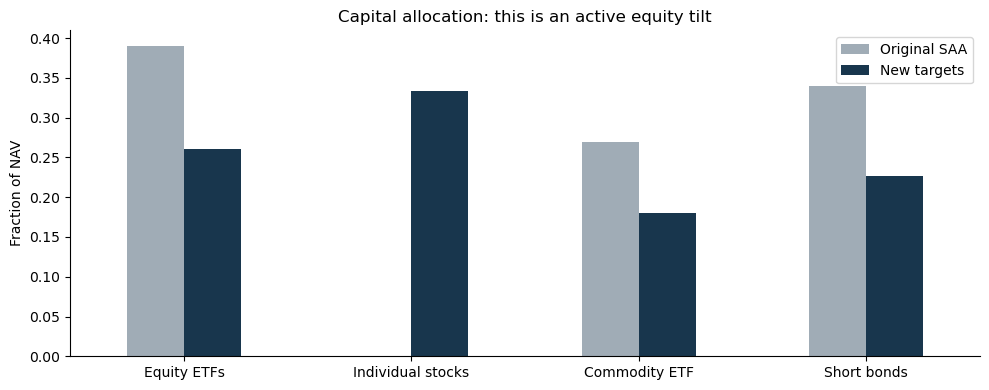

In [16]:
w=portfolio_weights(SELECTED,q);delta=w-benchmark
risk_table=[]
for name,cov in covariances.items():
    vv=cov.to_numpy();ww=w.to_numpy();bb=benchmark.to_numpy();dd=delta.to_numpy()
    risk_table.append({'Estimate':name,'Annual TE':np.sqrt(dd@vv@dd),
                       'Portfolio vol':np.sqrt(ww@vv@ww),'SAA vol':np.sqrt(bb@vv@bb)})
risk_table=pd.DataFrame(risk_table).set_index('Estimate')
display(risk_table.style.format('{:.2%}'))
normal_var=risk_table.loc['Monthly60',['Portfolio vol','SAA vol']]/np.sqrt(12)*norm.ppf(.95)
display(normal_var.rename('One-month 5% normal VaR, zero mean').to_frame().style.format('{:.2%}'))
checks=pd.DataFrame([
    ['Official / working class','3–6 positive-weight stocks',3<=int((w.loc[universe]>0).sum())<=6],
    ['Official','Long only',bool((w>=0).all())],
    ['Working class','One-third individual-stock targets',bool(np.isclose(w.loc[universe].sum(),STOCK_FRACTION))],
    ['Official','Monthly annual TE 2–5%',bool(.02<=risk_table.loc['Monthly60','Annual TE']<=.05)],
    ['Research preference','Daily63 TE at most 5%',bool(risk_table.loc['Daily63','Annual TE']<=.05)],
    ['Research preference','Largest stock at most 8%',bool(w.loc[universe].max()<=.08)],
],columns=['Type','Check','Met'])
display(checks)
mix=pd.DataFrame({'Original SAA':[SAA[['SPY','EEMV','SCHD']].sum(),0,SAA.DBC,SAA[['VGSH','STIP']].sum()],
                  'New targets':[w[['SPY','EEMV','SCHD']].sum(),w.loc[universe].sum(),w.DBC,w[['VGSH','STIP']].sum()]},
                 index=['Equity ETFs','Individual stocks','Commodity ETF','Short bonds'])
mix.plot.bar(title='Capital allocation: this is an active equity tilt',color=['#A0ACB6','#18364D']);plt.ylabel('Fraction of NAV');plt.xticks(rotation=0);plt.tight_layout();plt.show()

Monthly TE is within the required band. Daily TE exceeds our additional 5% preference, and Kroger is slightly above the 8% single-stock preference. Kroger and Hormel also put roughly 15% of NAV on the same reporting date.

## 10. Sensitivity to the assumptions

First we lower valuations at the chosen weights. We then recalculate the stock proportions to see how changing alphas affects concentration and risk.

In [17]:
base_alpha=forecast.loc[SELECTED,'Base annual alpha']
scenario_alphas={'Base':base_alpha,
                 'BMY and XOM alpha halved':base_alpha*pd.Series([1,1,1,.5,.5,1],index=SELECTED),
                 'XOM alpha zero':base_alpha*pd.Series([1,1,1,1,0,1],index=SELECTED),
                 'All values 10% lower':ALPHA_FRACTION*(1+forecast.loc[SELECTED,'k'])*(.9*forecast.loc[SELECTED,'Value USD']/forecast.loc[SELECTED,'Price USD']-1)}
stress=[]
for name,aa in scenario_alphas.items():
    z=portfolio_metrics(SELECTED,alphas=aa)
    stress.append({'Scenario':name,'Positive stocks':int((aa>0).sum()),'Full residual IR':z['Full residual IR'],
                   'Monthly TE':z['Monthly TE'],'Daily63 TE':z['Daily63 TE'],'Max stock':z['Max stock']})
display(pd.DataFrame(stress).set_index('Scenario'))
rc=residual_cov.loc[SELECTED,SELECTED].to_numpy();sd=np.sqrt(np.diag(rc));qq=q.to_numpy()
low5=ALPHA_FRACTION*(1+forecast.loc[SELECTED,'k'])*(.95*forecast.loc[SELECTED,'Value USD']/forecast.loc[SELECTED,'Price USD']-1)
display(pd.Series({'Base full-residual IR':selected_metrics['Full residual IR'],
                   'Fair values -5%, held weights':float(q@low5/np.sqrt(qq@rc@qq)),
                   'Correlations 20% toward one':float(q@base_alpha/np.sqrt(qq@(.8*rc+.2*np.outer(sd,sd))@qq)),
                   'Residual volatility +25%':selected_metrics['Full residual IR']/1.25}).to_frame('Expected IR sensitivity'))

cash_rows=[]
for ticker in SELECTED:
    k=forecast.loc[ticker,'k'];v=policy['valuation'][ticker];cash=cash_per_share[ticker]
    cash_rows.append({'Stock':ticker,'Price':entry_prices[ticker],
                     'Cash value':cash_value(cash,k,v['cash_growth'],v['terminal_growth']),
                     'k +1pp':cash_value(cash,k+.01,v['cash_growth'],v['terminal_growth']),
                     'k +2pp':cash_value(cash,k+.02,v['cash_growth'],v['terminal_growth'])})
display(pd.DataFrame(cash_rows).set_index('Stock').style.format('${:.2f}',na_rep='Unavailable'))

,Positive stocks,Full residual IR,Monthly TE,Daily63 TE,Max stock
Scenario,,,,,
Base,6,0.695860,0.039190,0.077403,0.081015
BMY and XOM alpha halved,6,0.660899,0.039822,0.082373,0.095238
XOM alpha zero,5,0.697576,0.040871,0.086840,0.090889
All values 10% lower,5,0.204292,0.044327,0.088212,0.093283


,Expected IR sensitivity
Base full-residual IR,0.695860
"Fair values -5%, held weights",0.426145
Correlations 20% toward one,0.522949
Residual volatility +25%,0.556688


,Price,Cash value,k +1pp,k +2pp
Stock,,,,
ADBE,$239.30,$270.38,$245.48,$224.68
KR,$67.70,$79.03,$65.91,$56.51
HRL,$21.95,$30.99,$25.37,$21.48
BMY,$62.14,$69.64,$59.88,$52.52
XOM,$165.87,Unavailable,Unavailable,Unavailable
HPQ,$28.46,$32.11,$28.90,$26.27


## 11. Staggered holding-period tests

We test 20, 33 and 63 trading sessions, starting on every eligible historical date. Each period begins at the chosen weights and holds the units unchanged. Adjusted prices assume reinvested distributions.

The baseline has zero fees. Separate 5, 10 and 25 bp entry-and-exit scenarios show the effect of costs. Replacing the stock basket with SPY provides a simple comparison.

These tests reuse today's stock choices and assumptions. We split the history before, after and across DBC's 10 November 2025 methodology change. Changes in market conditions also affect the comparison.

In [18]:
DBC_CHANGE=pd.Timestamp('2025-11-10')
def regime(start,end):return 'pre' if end<DBC_CHANGE else 'post' if start>=DBC_CHANGE else 'crossing'
control=benchmark*(1-STOCK_FRACTION);control['SPY']+=STOCK_FRACTION
replay_weights={'Selected six':w,'Unchanged SAA':benchmark,'One-third SPY control':control,
                'Pure residual-IR maximum':portfolio_weights(list(pure_max.stocks)),
                'Highest course IR':portfolio_weights(list(headline_max.stocks))}

def replay_all_starts(prices,weights,horizons=(20,33,63),cost_cases=(0,5,10,25)):
    returns=prices.pct_change().iloc[1:].to_numpy();bb=benchmark.to_numpy();records=[]
    for horizon in horizons:
        for start in range(len(returns)-horizon+1):
            growth=np.vstack([np.ones(len(bb)),np.cumprod(1+returns[start:start+horizon],axis=0)])
            bench=growth@bb;begin=prices.index[start];end=prices.index[start+horizon]
            for name,weights_series in weights.items():
                ww=weights_series.to_numpy();wealth=growth@ww
                entry=np.abs(ww-bb).sum()
                exit_turnover=np.abs(ww*growth[-1]/wealth[-1]-bb*growth[-1]/bench[-1]).sum()
                for bps in cost_cases:
                    net=wealth*(1-entry*bps/10000);net[0]=1;net[-1]*=1-exit_turnover*bps/10000
                    active_daily=net[1:]/net[:-1]-bench[1:]/bench[:-1]
                    active_te=active_daily.std(ddof=1)*np.sqrt(252)
                    records.append({'Portfolio':name,'Horizon':horizon,'Cost bps':bps,'Start position':start,
                                    'Start':begin,'End':end,'Regime':regime(begin,end),'Return':net[-1]-1,
                                    'Active return':net[-1]-bench[-1],'Drawdown':float((net/np.maximum.accumulate(net)-1).min()),
                                    'Realised active TE':active_te,
                                    'Realised IR':active_daily.mean()*252/active_te if active_te>1e-12 else np.nan})
    return pd.DataFrame(records)

replays=replay_all_starts(adjusted,replay_weights)
summary=replays.groupby(['Portfolio','Horizon','Cost bps','Regime'],sort=False).agg(
    Starts=('Return','size'),Mean_return=('Return','mean'),Mean_active=('Active return','mean'),
    Loss_rate=('Return',lambda x:(x<0).mean()),Beat_SAA=('Active return',lambda x:(x>0).mean()),
    Fifth_percentile=('Return',lambda x:x.quantile(.05)),Worst_drawdown=('Drawdown','min'),Median_realised_IR=('Realised IR','median'))
display(summary.xs((33,0,'post'),level=['Horizon','Cost bps','Regime']))
display(summary.loc['Selected six'].xs('post',level='Regime'))

,Starts,Mean_return,Mean_active,Loss_rate,Beat_SAA,Fifth_percentile,Worst_drawdown,Median_realised_IR
Portfolio,,,,,,,,
Selected six,217,0.023513,-0.003947,0.179724,0.442396,-0.019117,-0.052603,-0.267978
Unchanged SAA,217,0.027460,0.000000,0.156682,0.000000,-0.023921,-0.045365,NaN
One-third SPY control,217,0.025380,-0.002080,0.147465,0.428571,-0.013254,-0.042558,-0.462013
Pure residual-IR maximum,217,0.021409,-0.006051,0.188940,0.400922,-0.015399,-0.052066,-0.697641
Highest course IR,217,0.016763,-0.010698,0.248848,0.308756,-0.024486,-0.061518,-1.708634


Starts  Mean_return  Mean_active  Loss_rate  Beat_SAA  \
Horizon Cost bps                                                          
20      0            230     0.014463    -0.001453   0.204348  0.443478   
        5            230     0.013788    -0.002128   0.217391  0.430435   
        10           230     0.013113    -0.002803   0.226087  0.421739   
        25           230     0.011089    -0.004827   0.247826  0.391304   
33      0            217     0.023513    -0.003947   0.179724  0.442396   
        5            217     0.022834    -0.004627   0.188940  0.428571   
        10           217     0.022154    -0.005306   0.188940  0.414747   
        25           217     0.020117    -0.007343   0.193548  0.359447   
63      0            187     0.048091    -0.007482   0.000000  0.390374   
        5            187     0.047397    -0.008176   0.000000  0.379679   
        10           187     0.046704    -0.008869   0.000000  0.363636   
        25           187     0.044625    -0.010948   0.010695  0.299465   

                  Fifth_percentile  Worst_drawdown  Median_realised_IR  
Horizon Cost bps                                                        
20      0                -0.024036       -0.052603           -0.758708  
        5                -0.024680       -0.052603           -0.883850  
        10               -0.025325       -0.052603           -0.998855  
        25               -0.027256       -0.052986           -1.391192  
33      0                -0.019117       -0.052603           -0.267978  
        5                -0.019774       -0.052603           -0.352063  
        10               -0.020430       -0.052603           -0.458681  
        25               -0.022399       -0.053042           -0.750847  
63      0                 0.015481       -0.053997           -0.362104  
        5                 0.014805       -0.053997           -0.398519  
        10                0.014129       -0.054058           -0.434778  
        25                0.012102       -0.054960           -0.542451

217 overlapping starts represent only 6–7 non-overlapping periods per offset.


,Periods,Mean_active,Loss_rate
Start position,,,
0,6,-0.006154,0.333333
1,6,-0.007190,0.333333
2,6,-0.007566,0.333333
3,7,-0.004933,0.285714
4,7,-0.003605,0.142857
5,7,-0.003216,0.142857
6,7,-0.003523,0.142857
7,7,-0.003519,0.285714
8,7,-0.001987,0.142857


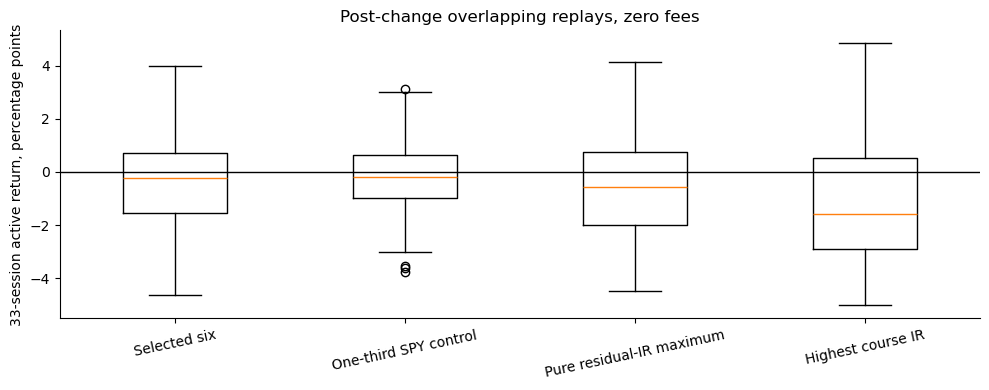

Historical results match the saved zero-fee calculation.


In [19]:
post33=replays[(replays.Portfolio=='Selected six')&(replays.Horizon==33)&(replays['Cost bps']==0)&(replays.Regime=='post')].copy()
phases=post33.groupby(post33['Start position']%33).agg(Periods=('Return','size'),Mean_active=('Active return','mean'),Loss_rate=('Return',lambda x:(x<0).mean()))
print(f'{len(post33)} overlapping starts represent only {phases.Periods.min()}–{phases.Periods.max()} non-overlapping periods per offset.')
display(phases)
fig,ax=plt.subplots(figsize=(10,4))
groups=[replays[(replays.Portfolio==name)&(replays.Horizon==33)&(replays['Cost bps']==0)&(replays.Regime=='post')]['Active return'].to_numpy()*100 for name in replay_weights if name!='Unchanged SAA']
labels=[name for name in replay_weights if name!='Unchanged SAA']
ax.boxplot(groups);ax.set_xticks(range(1,len(labels)+1),labels,rotation=12)
ax.axhline(0,color='black',lw=1);ax.set_ylabel('33-session active return, percentage points');ax.set_title('Post-change overlapping replays, zero fees');plt.tight_layout();plt.show()
if FINAL_CASE:
    archived=next(z for z in read_json('results/window_summary.json') if z['candidate']=='Rebuild' and z['horizon']==33 and z['regime']=='post')
    np.testing.assert_allclose(post33['Active return'].mean(),archived['mean_active'],atol=1e-10)
    np.testing.assert_allclose(post33.Return.quantile(.05),archived['q05_net_return'],atol=1e-10)
    assert len(post33)==217
    print('Historical results match the saved zero-fee calculation.')

Average active return is negative in the recent replay. Many starting dates share most of their observations, and each offset contains only a few non-overlapping periods. These results leave considerable uncertainty about performance during the challenge.

## 12. Forward risk checks

At each eligible Friday, we estimate risk from past data and compare it with realized active risk over the next 33 sessions. We also compare 60-month estimates with the following 6 and 12 months.

The forecasts use observations available at each date. The stock choices and weights still reflect research done with today's information.

,Origins,Median predicted TE,Median realised TE,Realised above5 given forecast pass
Estimator,,,,
Daily252,42.000000,0.047790,0.059648,0.535714
Daily63,42.000000,0.050251,0.059648,0.428571
EWMA252,42.000000,0.048872,0.059648,0.500000
Monthly60,42.000000,0.036336,0.059648,0.690476


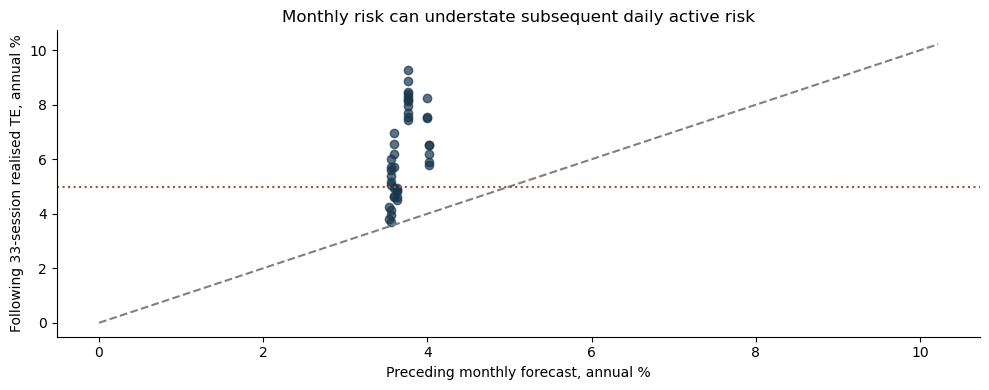

In [20]:
actual_month_ends=adjusted.index.to_series().groupby(adjusted.index.to_period('M')).last()
forward_monthly=monthly.copy()
forward_monthly.index=pd.DatetimeIndex([actual_month_ends.loc[date.to_period('M')] for date in monthly.index])
forward_rows=[]
for pos,origin in enumerate(adjusted.index[:-33]):
    if origin.weekday()!=4:continue
    train_m=forward_monthly.loc[:origin];train_d=daily.loc[:origin]
    if len(train_m)<60 or len(train_d)<252:continue
    test=daily.iloc[pos:pos+33]
    assert test.index[0]>origin and train_m.index[-1]<=origin and train_d.index[-1]<=origin
    growth=np.vstack([np.ones(len(TICKERS)),np.cumprod(1+test.to_numpy(),axis=0)])
    wealth=growth@w.to_numpy();bench=growth@benchmark.to_numpy()
    realised=(wealth[1:]/wealth[:-1]-bench[1:]/bench[:-1]).std(ddof=1)*np.sqrt(252)
    for name,cov in covariance_models(train_m,train_d).items():
        pred=float(np.sqrt(delta.to_numpy()@cov.to_numpy()@delta.to_numpy()))
        forward_rows.append({'Origin':origin,'End':test.index[-1],'Regime':regime(origin,test.index[-1]),
                             'Estimator':name,'Predicted TE':pred,'Realised TE':realised,
                             'Training end':train_m.index[-1],'Test first':test.index[0]})
forward=pd.DataFrame(forward_rows)
forward_summary=forward.groupby(['Estimator','Regime']).apply(
    lambda g:pd.Series({'Origins':len(g),'Median predicted TE':g['Predicted TE'].median(),
                       'Median realised TE':g['Realised TE'].median(),
                       'Realised above5 given forecast pass':(g.loc[g['Predicted TE'].between(.02,.05),'Realised TE']>.05).mean()}),include_groups=False)
display(forward_summary.xs('post',level='Regime'))
plot=forward[(forward.Estimator=='Monthly60')&(forward.Regime=='post')]
fig,ax=plt.subplots();ax.scatter(plot['Predicted TE']*100,plot['Realised TE']*100,color='#18364D',alpha=.7)
limit=max(plot['Predicted TE'].max(),plot['Realised TE'].max())*110
ax.plot([0,limit],[0,limit],color='grey',ls='--');ax.axhline(5,color='#A34F36',ls=':')
ax.set(xlabel='Preceding monthly forecast, annual %',ylabel='Following 33-session realised TE, annual %',title='Monthly risk can understate subsequent daily active risk');plt.tight_layout();plt.show()

In [21]:
matched=[]
for horizon in [6,12]:
    for pos in range(59,len(forward_monthly)-horizon):
        train=forward_monthly.iloc[pos-59:pos+1];test=forward_monthly.iloc[pos+1:pos+horizon+1]
        pred=float(np.sqrt(delta.to_numpy()@(train.cov().to_numpy()*12)@delta.to_numpy()))
        realised=float((test.to_numpy()@delta.to_numpy()).std(ddof=1)*np.sqrt(12))
        matched.append({'Months':horizon,'Origin':train.index[-1],'End':test.index[-1],
                        'Regime':regime(train.index[-1],test.index[-1]),'Predicted TE':pred,'Realised TE':realised})
matched=pd.DataFrame(matched)
display(matched.groupby(['Months','Regime']).agg(Origins=('Origin','size'),Median_predicted=('Predicted TE','median'),Median_realised=('Realised TE','median')))
if FINAL_CASE:
    archived=next(z for z in read_json('results/forward_summary.json') if z['candidate']=='Rebuild' and z['estimator']=='Monthly60' and z['regime']=='post')
    np.testing.assert_allclose(plot['Predicted TE'].median(),archived['median_pred_te'],atol=1e-10)
    np.testing.assert_allclose(plot['Realised TE'].median(),archived['median_realized_te'],atol=1e-10)
    assert len(plot)==42
    print('Forward risk estimates match the saved results.')

Origins  Median_predicted  Median_realised
Months Regime                                              
6      crossing        6          0.034815         0.037475
       post            6          0.035894         0.063218
       pre           103          0.037515         0.034454
12     crossing       12          0.034834         0.039212
       pre            97          0.037641         0.037234

Forward risk estimates match the saved results.


## 13. Information Ratio and the Sharpe link

The stock basket's residual IR, the whole portfolio's active IR and realized historical IR use different return and risk measures. We show each separately.

The theoretical Sharpe calculation uses an assumed SAA excess return. Its usefulness depends on the quality of the alpha assumptions and the portfolio mix.

In [22]:
ir_rows=[]
alpha_nav=selected_metrics['Annual alpha/NAV'];beta_port=selected_metrics['Portfolio beta SAA']
for estimator,row in risk_table.iterrows():
    expected_active=alpha_nav+(beta_port-1)*SAA_EXPECTED_EXCESS
    ir_rows.append({'Risk estimate':estimator,'Expected active IR,zero fees':expected_active/row['Annual TE'],
                    'Optional10bps entry/exit stress':(expected_active-(4/3)*.001/(33/252))/row['Annual TE']})
display(pd.DataFrame(ir_rows).set_index('Risk estimate'))
mu_saa=.04
saa_vol=risk_table.loc['Monthly60','SAA vol'];portfolio_vol=risk_table.loc['Monthly60','Portfolio vol']
saa_sharpe=mu_saa/saa_vol
display(pd.Series({'Assumed SAA annual excess return':mu_saa,'Scenario SAA Sharpe':saa_sharpe,
                   'Independent-residual unconstrained theory ceiling':np.sqrt(saa_sharpe**2+selected_metrics['Course IR']**2),
                   'Conditional Sharpe at actual one-third target':(beta_port*mu_saa+alpha_nav)/portfolio_vol}).to_frame('Supplementary Sharpe scenario'))

,"Expected active IR,zero fees",Optional10bps entry/exit stress
Risk estimate,,
Monthly60,0.680603,0.420795
Daily252,0.408256,0.252411
Daily63,0.344593,0.213051
EWMA252,0.355911,0.220048


,Supplementary Sharpe scenario
Assumed SAA annual excess return,0.040000
Scenario SAA Sharpe,0.507195
Independent-residual unconstrained theory ceiling,0.910207
Conditional Sharpe at actual one-third target,0.747831


## 14. Share quantities and trades

\[\text{base shares}_i=\left\lfloor\frac{w_i\times\text{post-loss NAV}}{P_i}\right\rfloor.\]

After rounding down, the team bought one additional SPY share and one additional Adobe share to reduce unused cash. Fees and the reserve are zero. Subtracting the original shares gives the trade list.

In [23]:
if FEE_BPS!=0:raise ValueError('This final implementation section is the zero-fee challenge case. Use cost stresses above for research.')
nav_decimal=Decimal(str(NAV));position_rows=[]
for ticker in ETFS+SELECTED:
    price=Decimal(str(entry_prices[ticker]));target=Decimal(str(w[ticker]))*nav_decimal
    base_shares=int((target/price).to_integral_value(rounding=ROUND_FLOOR))
    extra=EXTRA_SHARES.get(ticker,0);shares=base_shares+extra;value=shares*price
    original=int(opening_shares.get(ticker,0))
    position_rows.append({'Ticker':ticker,'Bloomberg identifier':ticker+' US Equity','Currency':'USD',
                          'Target NAV weight':w[ticker],'Price USD':float(price),'Base rounded shares':base_shares,
                          'Additional shares reported':extra,'Final shares':shares,'Trade shares':shares-original,
                          'Position USD':float(value),'Actual NAV weight':float(value/nav_decimal)})
positions=pd.DataFrame(position_rows).set_index('Ticker')
invested=sum(Decimal(str(x)) for x in positions['Position USD'])
cash=nav_decimal-invested
stock_value=sum(Decimal(str(x)) for x in positions.loc[SELECTED,'Position USD'])
assert cash>=0
display(positions)
print(f'Post-loss NAV: ${NAV:,.2f}; target stocks: ${stock_budget:,.2f}; actual stock value: ${stock_value:,.2f}')
print(f'Actual stock fraction: {float(stock_value/nav_decimal):.8%}; cash: ${cash:,.2f}; fees/reserve: $0.00')

actual_w=pd.Series(0.,index=TICKERS)
actual_w.loc[positions.index]=positions['Actual NAV weight']
actual_monthly=calibration.dot(actual_w)
actual_te=(actual_monthly-calibration[ETFS].dot(SAA)).std(ddof=1)*np.sqrt(12)
print(f'Whole-share monthly annual TE: {actual_te:.5%}. Cash earns no interest.')

,Bloomberg identifier,Currency,Target NAV weight,Price USD,Base rounded shares,Additional shares reported,Final shares,Trade shares,Position USD,Actual NAV weight
Ticker,,,,,,,,,,
SPY,SPY US Equity,USD,0.173867,735.290000,22963,1,22964,-11205,"16,885,199.560000",0.173868
EEMV,EEMV US Equity,USD,0.064400,69.710000,89717,0,89717,-43893,"6,254,172.070000",0.064400
DBC,DBC US Equity,USD,0.179667,31.540000,553213,0,553213,-245543,"17,448,338.020000",0.179667
SCHD,SCHD US Equity,USD,0.021867,35.170000,60380,0,60380,-35108,"2,123,564.600000",0.021866
VGSH,VGSH US Equity,USD,0.033333,57.860000,55948,0,55948,-30723,"3,237,151.280000",0.033333
STIP,STIP US Equity,USD,0.193533,100.510000,186996,0,186996,-101634,"18,794,967.960000",0.193533
ADBE,ADBE US Equity,USD,0.046484,239.300000,18864,1,18865,18865,"4,514,394.500000",0.046485
KR,KR US Equity,USD,0.081015,67.700000,116215,0,116215,116215,"7,867,755.500000",0.081015
HRL,HRL US Equity,USD,0.068974,21.950000,305167,0,305167,305167,"6,698,415.650000",0.068974


Post-loss NAV: $97,115,068.58; target stocks: $32,371,689.53; actual stock value: $32,371,559.04
Actual stock fraction: 33.33319897%; cash: $116.05; fees/reserve: $0.00
Whole-share monthly annual TE: 3.91896%. Cash earns no interest.


## 15. Cash-flow review

The companion notebook develops the FCFF and FCFE models, implied growth and return-timing scenarios. At the same holdings, BMY has the smallest cash-value cushion and Adobe remains sensitive to lower cash generation.

The table below compares the earnings values with the completed cash-flow checks.

In [24]:
cash_review=pd.read_csv(ROOT/'results/valuation/valuations.csv').set_index('ticker').loc[SELECTED]
display(cash_review[['price','multiple_value','dcf_value','decision_value','implied_growth','dcf_wacc']])
print('Residual IR using the lower cash-flow values:',read_json('results/valuation/portfolio.json')['chosen']['audit_full_residual_ir'])
print('Bloomberg entry: 7 November 2026, using 6 November closing prices.')

,price,multiple_value,dcf_value,decision_value,implied_growth,dcf_wacc
ticker,,,,,,
ADBE,239.300000,290.320000,271.142181,271.142181,0.048892,0.130807
KR,67.700000,78.000000,87.451431,78.000000,0.007021,0.063070
HRL,21.950000,25.160000,31.488280,25.160000,-0.005862,0.061996
BMY,62.140000,70.950000,65.498302,65.498302,-0.009526,0.058268
XOM,165.870000,180.000000,213.084181,180.000000,0.002892,0.058265
HPQ,28.460000,32.130000,34.444922,32.130000,0.015668,0.109364


Residual IR using the lower cash-flow values: 0.5639104684151648
Bloomberg entry: 7 November 2026, using 6 November closing prices.


## 16. Sources

The register below links the saved prices, statements and issuer evidence. Peer comparisons use the 5 November snapshot; share quantities use 6 November closes. The valuation multiples, cash assumptions and alpha haircut are our judgments.

In [25]:
display(pd.DataFrame(source_register,columns=['Source','Location','Use']).assign(ID=lambda x:[f'S{i:02d}'for i in range(1,len(x)+1)]).set_index('ID'))
print('Source register complete.')

,Source,Location,Use
ID,,,
S01,Course,"Local Round2 guidelines, Class3 PartII and Class5 texts",Original SAA benchmark;3-6 long stocks;60 monthly USD returns; annual TE2-5%. One-third is the r...
S02,Prices,https://query1.finance.yahoo.com/v8/finance/chart/{TICKER},Complete November6close. Raw and adjusted daily prices archived. Separate ledger corrects missin...
S03,Statements,https://query1.finance.yahoo.com/ws/fundamentals-timeseries/v1/finance/timeseries/{TICKER},Annual and quarterly statements available November6. Flow sums and balances remain distinct. Mis...
S04,Estimates,https://query1.finance.yahoo.com/v10/finance/quoteSummary/{TICKER},Analyst adjusted estimates remain separate from issuer GAAP guidance and normalized earnings.
S05,Rates,https://fred.stlouisfed.org/series/DGS10,"10-year input 4.84%, observation 2026-11-05. Latest1-month 4.03%, observation 2026-11-05. Histor..."
S06,ADBE guidance,https://www.sec.gov/Archives/edgar/data/796343/000079634326000147/adbeex991q326.htm,FY26GAAP EPS18.12-18.17; midpoint18.145.
S07,ADBE event,https://www.adobe.com/investor-relations/calendar.html,"December9results, issuer calendar."
S08,KR guidance,https://ir.kroger.com/news/news-details/2026/Kroger-Reports-Second-Quarter-2026-Results-and-Upda...,FY26adjusted EPS5.10-5.30; reaffirmed October20before entry.
S09,KR event,https://ir.kroger.com/news/news-details/2026/Kroger-Announces-Third-Quarter-Conference-Call-with...,"December3results, issuer announcement dated November5."


Source register complete.
